In [ ]:
import os
import json
import pandas as pd
from PIL import Image

In [16]:
DATA_PATH = "/content/drive/MyDrive/Applied AI VQA Project/VQA Dataset/"
questions_file = DATA_PATH + "questions/v2_OpenEnded_mscoco_val2014_questions.json"
annotations_file = DATA_PATH + "annotations/v2_mscoco_val2014_annotations.json"
images_path = DATA_PATH + "images/val2014/"

In [14]:
def retrieve_image(image_id, images_path):
    """
    Retrieve an image from the COCO validation folder using the image_id.

    Parameters
    ----------
    image_id : int
        COCO image identifier.
    images_path : str
        Path to the directory containing images.

    Returns
    -------
    PIL.Image
        Loaded image.
    """

    image_name = f"COCO_val2014_{image_id:012d}.jpg"
    image_path = os.path.join(images_path, image_name)

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    img = Image.open(image_path).convert("RGB")
    return img

In [15]:
def create_vqa_dataset(questions_file, annotations_file, max_samples=None):
    """
    Create a structured VQA dataset DataFrame.

    Each row corresponds to one question associated with an image.

    Columns
    -------
    image_id : int
    question : str
    answer : str

    Parameters
    ----------
    questions_file : str
        Path to the VQA questions JSON file.

    annotations_file : str
        Path to the VQA annotations JSON file.

    max_samples : int or None
        Optional limit to dataset size for debugging or fast experiments.

    Returns
    -------
    pandas.DataFrame
        Structured dataset.
    """

    # ----- check file existence -----

    if not os.path.exists(questions_file):
        raise FileNotFoundError(f"Questions file not found: {questions_file}")

    if not os.path.exists(annotations_file):
        raise FileNotFoundError(f"Annotations file not found: {annotations_file}")

    # ----- load JSON files -----

    with open(questions_file, "r") as f:
        questions_data = json.load(f)

    with open(annotations_file, "r") as f:
        annotations_data = json.load(f)

    questions_list = questions_data.get("questions", [])
    annotations_list = annotations_data.get("annotations", [])

    # ----- build mapping question_id -> answer -----

    answers_map = {
        ann["question_id"]: ann["multiple_choice_answer"]
        for ann in annotations_list
    }

    dataset_rows = []

    # ----- iterate over questions -----

    for i, q in enumerate(questions_list):

        if max_samples is not None and i >= max_samples:
            break

        qid = q["question_id"]
        image_id = q["image_id"]
        question = q["question"]

        answer = answers_map.get(qid)

        # skip entries without annotation
        if answer is None:
            continue

        dataset_rows.append({
            "image_id": image_id,
            "question": question,
            "answer": answer
        })

    df = pd.DataFrame(dataset_rows)

    return df

In [20]:
import matplotlib.pyplot as plt
import numpy as np

def show_image_with_all_qas(df, images_path):
    """
    Display a random image and all its associated questions and answers from the dataset.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset containing columns ['image_id', 'question', 'answer'].
    images_path : str
        Path to the folder containing COCO images.

    Returns
    -------
    None
    """

    if df.empty:
        print("Dataset is empty")
        return

    # 1. select a random row
    i = np.random.randint(0, df.shape[0])
    sample = df.iloc[i, :]
    image_id = sample["image_id"]

    # 2. get all rows corresponding to the same image
    image_rows = df[df["image_id"] == image_id]

    # 3. retrieve image
    try:
        img = retrieve_image(image_id, images_path)
    except FileNotFoundError as e:
        print(e)
        return

    # 4. prepare the text with all questions and answers
    qa_text = ""
    for idx, row in image_rows.iterrows():
        q = row.get("question", "N/A")
        a = row.get("answer", "N/A")
        qa_text += f"Q: {q}\nA: {a}\n\n"

    # 5. display image without axes
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Image ID: {image_id}", fontsize=12)
    plt.show()

    # 6. print all Q&A below
    print(qa_text)

In [17]:
# Creating the dataset
df = create_vqa_dataset(questions_file, annotations_file)

In [18]:
# overview
df.head()

,image_id,question,answer
0,262148,Where is he looking?,down
1,262148,What are the people in the background doing?,watching
2,262148,What is he on top of?,picnic table
3,393225,What website copyrighted the picture?,foodiebakercom
4,393225,Is this a creamy soup?,no


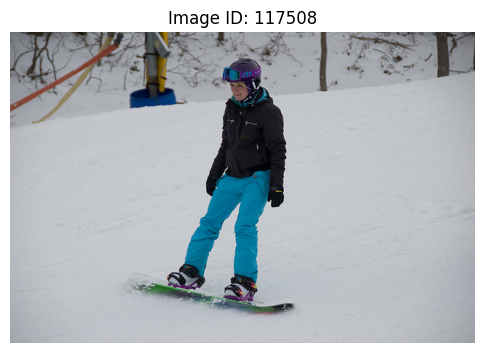

Q: How many of the women are currently wearing goggles on their faces?
A: 1

Q: Is the man wearing skis?
A: no

Q: What is he doing?
A: snowboarding

Q: Why is the woman wearing glasses?
A: no

Q: How many tree trunks are visible?
A: 2

Q: Are they at the beach?
A: no

Q: What are these people doing?
A: snowboarding

Q: What season is it?
A: winter

Q: What sport is being played?
A: snowboarding

Q: Is this man snowboarding?
A: yes

Q: What color jacket does this person have on?
A: black

Q: Is this person going to fall backwards?
A: no

Q: Would you rather be snowboarding or snow skiing right now?
A: snowboarding

Q: How many people are wearing blue?
A: 1

Q: What sport is he doing?
A: snowboarding




In [22]:
# Usage example
show_image_with_all_qas(df, images_path)